In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

df = pd.read_csv('../mini_project_1_DS02_05_26/dataset/credit_risk_dataset_EDA.csv')

df['loan_int_rate'] = pd.to_numeric(df['loan_int_rate'], errors='coerce')

X = df.drop(columns=['loan_int_rate'])
y = df['loan_int_rate']
print('X:', X.shape, ' y:', y.shape)
X.head()

X: (31529, 19)  y: (31529,)


,person_age,person_income,person_emp_length,loan_amnt,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_grade_encoded,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,log_person_income,cred_hist_to_age
0,22,59000,123.0,35000,1,0.59,1,3,3,0,0,0,1,0,0,0,1,10.985310,0.130435
1,21,9600,5.0,1000,0,0.10,0,2,1,1,0,0,0,0,0,1,0,9.169623,0.090909
2,25,9600,1.0,5500,1,0.57,0,3,2,0,0,1,0,0,0,0,0,9.169623,0.115385
3,23,65500,4.0,35000,1,0.53,0,2,2,0,0,1,0,0,0,0,1,11.089821,0.083333
4,24,54400,8.0,35000,1,0.55,1,4,2,0,0,1,0,0,0,0,1,10.904138,0.160000


In [2]:

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

print('Wytrenowano na', len(X_train), 'przykładach, test:', len(X_test))

Wytrenowano na 25223 przykładach, test: 6306


In [4]:
y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f'R^2 (zbior testowy):  {r2:.3f}')
print(f'RMSE (zbior testowy): {rmse:.4f}')

y_pred_train = model.predict(X_train)
print(f'R^2 (zbior treningowy): {r2_score(y_train, y_pred_train):.3f}')

R^2 (zbior testowy):  0.789
RMSE (zbior testowy): 1.4134
R^2 (zbior treningowy): 0.794


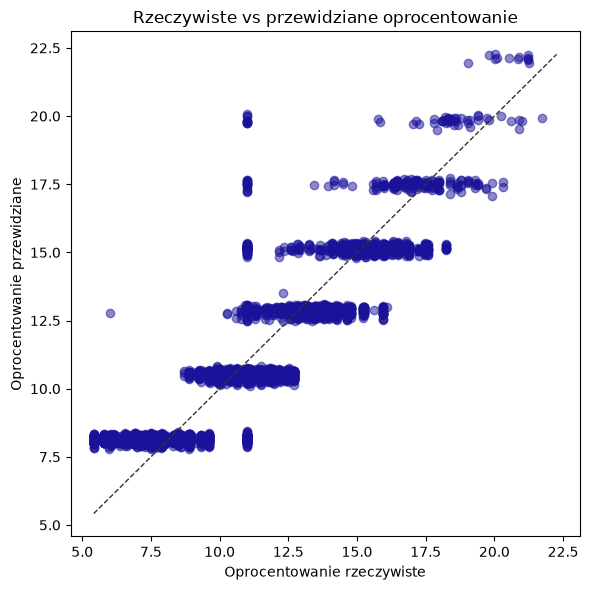

In [5]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, y_pred, alpha=0.5, color="#1a1399")
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
ax.plot(lims, lims, '--', color='#333333', linewidth=1)
ax.set_xlabel('Oprocentowanie rzeczywiste')
ax.set_ylabel('Oprocentowanie przewidziane')
ax.set_title('Rzeczywiste vs przewidziane oprocentowanie')
plt.tight_layout()
plt.show()

In [6]:
coefs = pd.Series(model.coef_, index=X.columns).sort_values()
print(f'Wyraz wolny (intercept, b): {model.intercept_:.4f}')
coefs

Wyraz wolny (intercept, b): 8.7794


loan_status                   -1.859092e-01
log_person_income             -6.545189e-02
loan_intent_HOMEIMPROVEMENT   -1.679852e-02
loan_percent_income           -7.020267e-03
person_emp_length             -6.348281e-03
person_age                    -3.930231e-03
person_home_ownership_OTHER   -1.553984e-03
person_income                  3.759632e-07
loan_amnt                      8.889277e-06
cred_hist_to_age               2.398334e-04
cb_person_default_on_file      1.130599e-03
loan_intent_VENTURE            6.708477e-03
loan_intent_EDUCATION          6.876363e-03
cb_person_cred_hist_length     7.883299e-03
loan_intent_MEDICAL            2.795351e-02
loan_intent_PERSONAL           3.544471e-02
person_home_ownership_OWN      1.268419e-01
person_home_ownership_RENT     1.769168e-01
loan_grade_encoded             2.342362e+00
dtype: float64

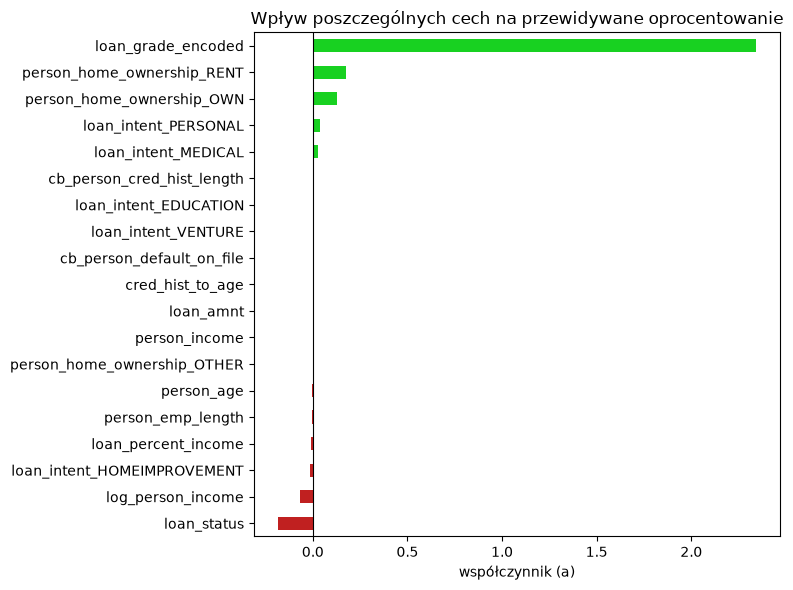

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))
coefs.plot(kind='barh', color=["#18D121" if c > 0 else "#c02020" for c in coefs], ax=ax)
ax.set_title('Wpływ poszczególnych cech na przewidywane oprocentowanie')
ax.set_xlabel('współczynnik (a)')
ax.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

## Wnioski

Wyniki na zbiorze treningowym i testowym są niemal identyczne ($0.794$ vs $0.789$), co świadczy o tym, że model dobrze generalizuje wiedzę na nowych danych - brak przeuczenia

`loan_grade_encoded` (Ocena ryzyka) - Posiada zdecydowanie najwyższy dodatni współczynnik wynoszący +2.3424. Oznacza to, że gorsza klasa ryzyka pożyczki silnie podnosi jej oprocentowanie

`log_person_income` (Logarytm dochodu klienta) - ma ujemny współczynnik (-0.0655), co potwierdza, że osoby o wyższych dochodach uzyskują korzystniejsze (niższe) oprocentowanie.

Wytrenowany model regresji liniowej poprawnie odzwierciedla rynkowe i ryzykowne uwarunkowania kredytowe. Głównym driverem podnoszącym oprocentowanie jest ocena punktowa/klasa ryzyka (loan_grade_encoded), podczas gdy wyższy dochód oraz wybrane cele pożyczkowe sprzyjają uzyskaniu lepszych warunków.